# Taller de Aprendizaje No Supervisado
## Parte 2: Segmentación de Clientes de Tarjeta de Crédito (variables numéricas)

### Credit Card Dataset

[Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)

Resume el comportamiento de uso de unos **9.000 titulares** de tarjeta durante los últimos 6 meses, con **17 variables numéricas de comportamiento** (saldo, compras, adelantos de efectivo, límite de crédito, pagos...).

> **Diferencia clave con el dataset de setas:** aquí **no hay etiqueta**. El objetivo *es* encontrar segmentos de clientes para definir una estrategia de marketing. Esto es aprendizaje no supervisado «de verdad»: no podemos calcular ARI porque no hay verdad de referencia; nos guiamos por métricas internas y por la **interpretabilidad** de los segmentos.

Además, al ser numérico y con escalas muy distintas, aparecen dos pasos que con las setas no hicieron falta: **imputar nulos** y **escalar**.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

**Qué hacemos:** cargamos las herramientas. `pandas` y `numpy` manejan los datos, `matplotlib` y `seaborn` dibujan, y `scikit-learn` aporta escalado, PCA, clustering y métricas. `RANDOM_STATE = 42` hace que los pasos aleatorios sean repetibles.

### Leer conjunto de datos y primer vistazo

In [2]:
# Leer el csv (esta en 'data/credit_card.csv') y mostrar las primeras filas.
df = pd.read_csv('data/credit_card.csv')
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Qué observamos:** cada fila es un cliente y cada columna resume su comportamiento.

| Variables | Qué miden |
|---|---|
| `CUST_ID` | Identificador del cliente |
| `BALANCE`, `BALANCE_FREQUENCY` | Saldo y con qué frecuencia se actualiza |
| `PURCHASES`, `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES` | Importe de compras: total, de una sola vez y en cuotas |
| `PURCHASES_FREQUENCY`, `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de cada tipo de compra |
| `CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY`, `CASH_ADVANCE_TRX` | Adelantos de efectivo: importe, frecuencia y número |
| `PURCHASES_TRX` | Número de compras |
| `CREDIT_LIMIT` | Límite de crédito |
| `PAYMENTS`, `MINIMUM_PAYMENTS`, `PRC_FULL_PAYMENT` | Pagos, pagos mínimos y proporción de pago total |
| `TENURE` | Antigüedad del servicio, en meses |

### Exploración de datos

In [3]:
# Tamano del dataset.
df.shape

(8950, 18)

In [4]:
# Descripcion estadistica. Fijaos en las escalas tan distintas entre variables.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


In [5]:
# Tipos de datos.
df.info()
print('Filas duplicadas:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

**Qué observamos:** hay 8950 clientes y 18 columnas, sin filas duplicadas. Salvo `CUST_ID`, todas son numéricas. Las escalas son muy distintas: unas frecuencias van de 0 a 1 y algunos importes superan los 40 000.

`CASH_ADVANCE_FREQUENCY` llega a 1,5, algo llamativo para una frecuencia; conviene señalarlo como posible problema de calidad del dato.

#### Nulos

In [6]:
# Contar nulos por variable (mostrad solo las que tengan).
nulos = df.isnull().sum()
nulos[nulos > 0]

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

**Qué hacemos:** `isnull().sum()` cuenta los valores faltantes y filtramos las columnas que tienen alguno.

Hay nulos en `CREDIT_LIMIT` (1) y `MINIMUM_PAYMENTS` (~313). Al ser variables numéricas muy sesgadas, los imputamos con la **mediana** (más robusta que la media).

In [7]:
# 1. Eliminar CUST_ID (es un identificador)
# 2. Imputar los nulos con la mediana de cada columna
df = df.drop(columns='CUST_ID')
df = df.fillna(df.median())
print(df.shape, '| nulos restantes:', df.isnull().sum().sum())

(8950, 17) | nulos restantes: 0


**Por qué:** `CUST_ID` solo identifica al cliente, no describe su comportamiento. Usamos la mediana porque los valores extremos la afectan poco: en `MINIMUM_PAYMENTS` la mediana es ≈ 312 y la media ≈ 864.

#### Distribución de algunas variables

Muchas variables están **muy sesgadas** (la mayoría de clientes gasta poco y unos pocos muchísimo). Esto es típico en datos financieros.

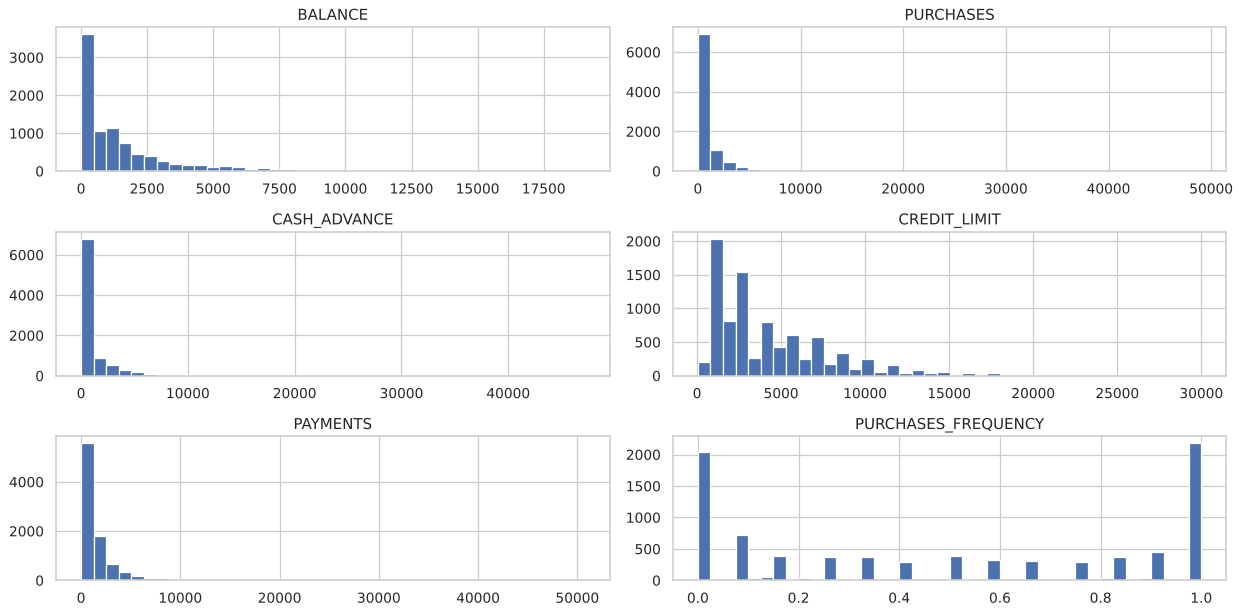

MINIMUM_PAYMENTS                    13.85
ONEOFF_PURCHASES                    10.05
PURCHASES                            8.14
INSTALLMENTS_PURCHASES               7.30
PAYMENTS                             5.91
CASH_ADVANCE_TRX                     5.72
CASH_ADVANCE                         5.17
PURCHASES_TRX                        4.63
BALANCE                              2.39
PRC_FULL_PAYMENT                     1.94
CASH_ADVANCE_FREQUENCY               1.83
ONEOFF_PURCHASES_FREQUENCY           1.54
CREDIT_LIMIT                         1.52
PURCHASES_INSTALLMENTS_FREQUENCY     0.51
PURCHASES_FREQUENCY                  0.06
BALANCE_FREQUENCY                   -2.02
TENURE                              -2.94
dtype: float64

In [8]:
# Pintar histogramas de unas cuantas variables (df[cols].hist...) y observar el sesgo.
cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'PURCHASES_FREQUENCY']
df[cols].hist(bins=40, figsize=(14, 7))
plt.tight_layout()
plt.show()
df.skew().sort_values(ascending=False).round(2)

**Cómo leerlo:** en un histograma, cada barra cuenta clientes en un rango. En los importes se acumulan cerca de cero y hay una cola larga a la derecha. `skew()` mide esa asimetría: cerca de 0 es simétrica y un valor muy positivo indica cola a la derecha.

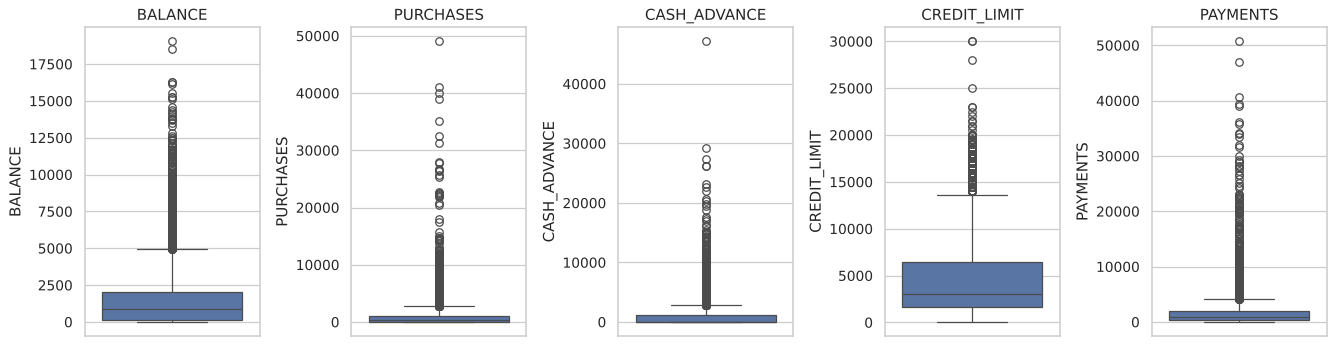

In [9]:
# Atípicos: diagramas de caja
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, col in zip(axes, cols[:5]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Cómo leerlo:** la caja contiene el 50 % central de los clientes y la línea interior es la mediana. Los puntos alejados son valores atípicos según la regla del diagrama.

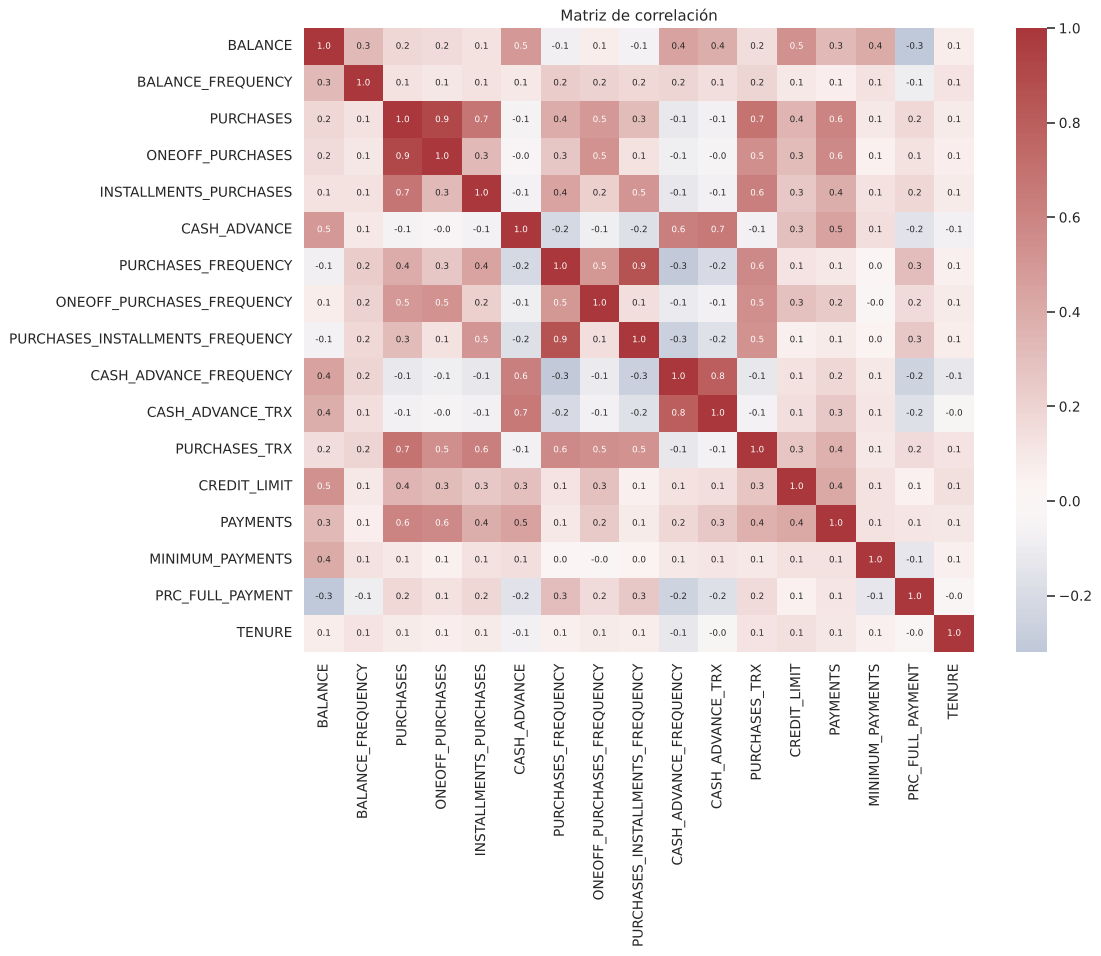

In [10]:
# Correlaciones entre variables
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap='vlag', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Matriz de correlación')
plt.show()

Hay variables muy relacionadas (por ejemplo `PURCHASES` con `ONEOFF_PURCHASES`, o `CASH_ADVANCE_FREQUENCY` con `CASH_ADVANCE_TRX`). Los valores extremos parecen comportamientos posibles de clientes, así que no los eliminamos; hay que tener presente que influyen en K-Means. Mantenemos las 17 variables porque todas describen comportamiento; solo descartamos el identificador.

### Escalado

K-Means, PCA y casi todos los algoritmos de distancia son **sensibles a la escala**. `CREDIT_LIMIT` llega a miles y `PURCHASES_FREQUENCY` está entre 0 y 1: sin escalar, las variables grandes dominarían. Estandarizamos (media 0, desviación 1).

In [11]:
# Aplicar StandardScaler a df -> X (array escalado)
scaler = StandardScaler()
X = scaler.fit_transform(df)
print(X.shape, X.mean().round(3), X.std().round(3))

(8950, 17) 0.0 1.0


**Qué observamos:** `StandardScaler` resta la media de cada columna y divide por su desviación estándar. La salida comprueba que la media global queda en 0 y la desviación en 1. Escalar no elimina el sesgo ni los atípicos.

## PCA

Con 17 variables no podemos pintar un scatter directo. Usamos PCA para (1) ver cuánta información retiene cada componente y (2) proyectar a 2D.

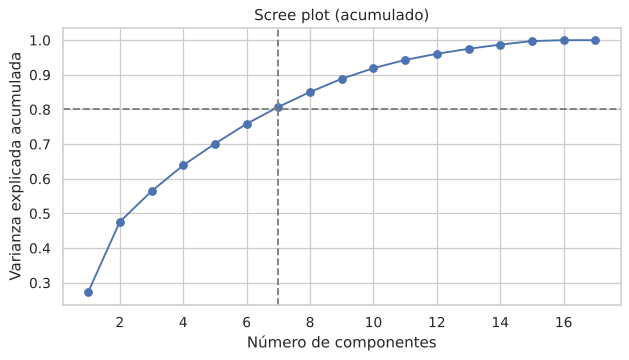

Componentes para ~80 % de varianza: 7 (80.8%)


In [12]:
# 1. Ajustar PCA sin fijar n_components y mirar explained_variance_ratio_
# 2. Pintar la varianza explicada acumulada (scree plot)
# 3. Decidir cuantas componentes hacen falta para ~80% de varianza
pca_full = PCA().fit(X)
acumulada = pca_full.explained_variance_ratio_.cumsum()
n80 = int(np.argmax(acumulada >= 0.80)) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(acumulada) + 1), acumulada, marker='o')
plt.axhline(0.80, color='grey', ls='--'); plt.axvline(n80, color='grey', ls='--')
plt.xlabel('Número de componentes'); plt.ylabel('Varianza explicada acumulada')
plt.title('Scree plot (acumulado)')
plt.show()
print(f'Componentes para ~80 % de varianza: {n80} ({acumulada[n80 - 1]:.1%})')

**Cómo leerlo:** PCA combina las variables en componentes ordenadas según la varianza que retienen. La curva las va sumando: se necesitan 7 de 17 para superar el 80 %.

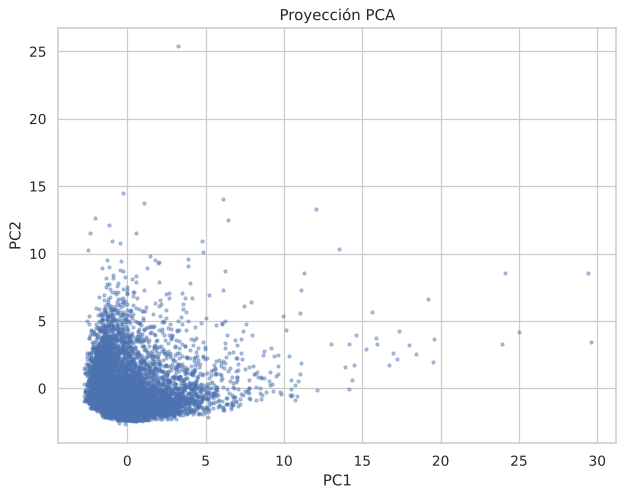

Varianza retenida en 2D: 0.476


In [13]:
# Proyectar X a 2 componentes y pintar el scatter (aun sin colores: no hay etiqueta)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca2.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=6, alpha=0.4)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Proyección PCA')
plt.show()
print('Varianza retenida en 2D:', round(pca2.explained_variance_ratio_.sum(), 3))

**Qué hacemos:** usamos solo dos componentes para dibujar. Retienen el 47,6 % de la varianza, así que el gráfico pierde bastante información.

A diferencia de las setas, aquí no vemos grupos separados a simple vista: es más bien una **nube continua**. El clustering nos ayudará a trazar fronteras útiles dentro de ella.

## Clustering: ¿cuántos segmentos? Codo + Silhouette

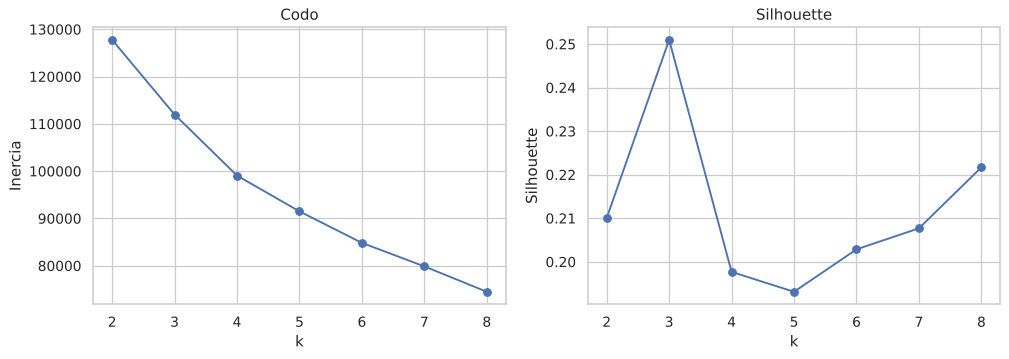

best_k = 3 | silhouette = 0.251


In [14]:
# Pintar las dos curvas y elegir best_k (el de mayor silhouette)
k_values = range(2, 9)
inercias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, inercias, marker='o'); axes[0].set(title='Codo', xlabel='k', ylabel='Inercia')
axes[1].plot(k_values, silhouettes, marker='o'); axes[1].set(title='Silhouette', xlabel='k', ylabel='Silhouette')
plt.show()

best_k = list(k_values)[int(np.argmax(silhouettes))]
print('best_k =', best_k, '| silhouette =', round(max(silhouettes), 3))

**Cómo funciona:** K-Means asigna cada cliente al centro más cercano. La inercia mide la compacidad (menor es más compacto, pero siempre tiende a bajar al aumentar k). La silhouette compara la cercanía al propio grupo con la cercanía a otros: va de -1 a 1 y más alto es mejor.

La silhouette es máxima con **k = 3**, aunque su valor (≈ 0,25) es bajo: los segmentos se solapan. El codo no marca un punto claro.

### K-Means final

In [15]:
# Entrenar KMeans con best_k, guardar las etiquetas y mirar el tamano de cada cluster
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_km = kmeans.labels_
pd.Series(labels_km).value_counts().sort_index()

0    1275
1    6114
2    1561
Name: count, dtype: int64

**Qué observamos:** los tres grupos tienen 6114, 1561 y 1275 clientes. El número de cada cluster es solo una etiqueta, no indica un orden.

### Comparativa de algoritmos

Sin etiqueta, comparamos con **métricas internas**: *silhouette* y *Calinski-Harabasz* (más alto = mejor) y *Davies-Bouldin* (más bajo = mejor).

In [16]:
# Definir evaluar(nombre, labels, X) con silhouette, davies_bouldin y calinski_harabasz
# (sin ARI: no hay etiqueta). Comparar KMeans, Aglomerativo y GMM.
def evaluar(nombre, labels, X):
    return {'modelo': nombre,
            'silhouette': silhouette_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels),
            'tamaños': sorted(np.bincount(labels).tolist(), reverse=True)}

modelos = {
    'KMeans': labels_km,
    'Aglomerativo': AgglomerativeClustering(n_clusters=best_k).fit_predict(X),
    'GMM': GaussianMixture(n_components=best_k, random_state=RANDOM_STATE).fit_predict(X),
}
display(pd.DataFrame([evaluar(n, l, X) for n, l in modelos.items()]).round(3))

# ¿Coinciden entre sí? ARI entre modelos (no es contra una verdad de referencia)
for n in ['Aglomerativo', 'GMM']:
    print(f'Acuerdo KMeans vs {n}: ARI = {adjusted_rand_score(labels_km, modelos[n]):.3f}')

,modelo,silhouette,davies_bouldin,calinski_harabasz,tamaños
0,KMeans,0.251,1.592,1605.026,"[6114, 1561, 1275]"
1,Aglomerativo,0.167,1.850,1239.326,"[4875, 2881, 1194]"
2,GMM,0.098,2.997,815.782,"[3410, 2934, 2606]"


Acuerdo KMeans vs Aglomerativo: ARI = 0.360
Acuerdo KMeans vs GMM: ARI = 0.069


**Cómo leer las métricas:** silhouette y Calinski-Harabasz son mejores cuanto más altas; Davies-Bouldin, cuanto más bajo. El Aglomerativo une grupos progresivamente y GMM modela los datos como una mezcla de distribuciones gaussianas. El ARI de esta celda solo mide cuánto coinciden dos modelos.

K-Means gana en las tres métricas internas. Los otros dos modelos coinciden poco con él (sobre todo GMM), así que **la segmentación depende bastante del algoritmo elegido**. Nos quedamos con K-Means por sus métricas y porque sus perfiles se interpretan bien.

### Dendrograma

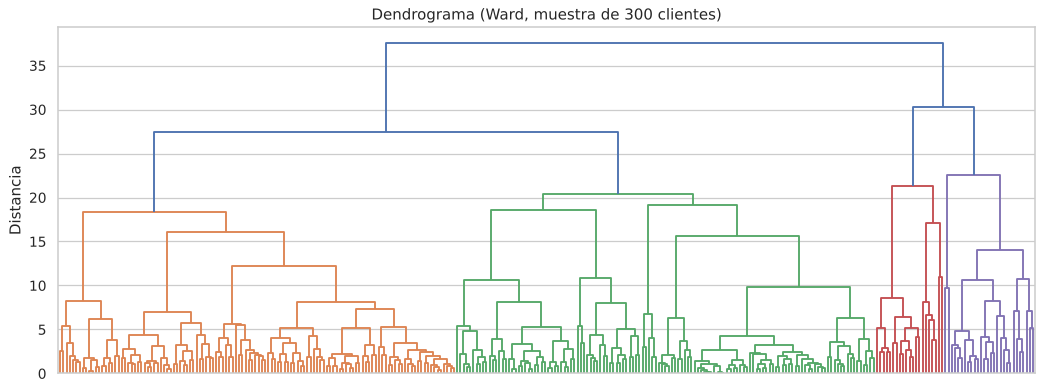

In [17]:
# linkage + dendrogram sobre una muestra de X
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X), size=300, replace=False)
Z = linkage(X[idx], method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True)
plt.title('Dendrograma (Ward, muestra de 300 clientes)'); plt.ylabel('Distancia')
plt.show()

**Cómo leerlo:** abajo cada hoja es un cliente de una muestra de 300. Las ramas se unen de abajo arriba y cuanto más alta es la unión, más distintos son los grupos. Los colores salen de un umbral automático y no fijan el número de segmentos.

### DBSCAN: ¿hay clusters de densidad aquí?

Probamos DBSCAN sobre la proyección PCA(2). Tiende a juntar casi todo en **un solo cluster**, con unos pocos grupos diminutos y el resto como **ruido**. Esto apunta a que, al menos en esta proyección, los datos son una nube continua. Aquí DBSCAN sirve mejor para **detectar atípicos** que para segmentar.

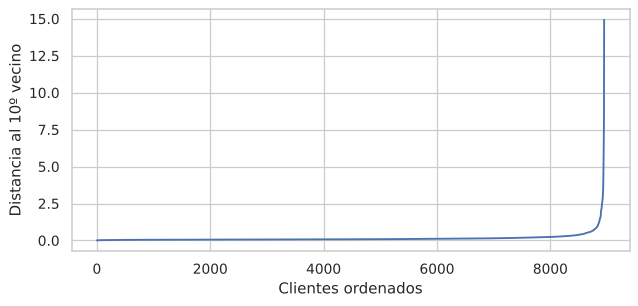

 0    8681
-1     239
 1      13
 3       9
 2       8
Name: count, dtype: int64

Clusters: 4 | ruido: 2.7%


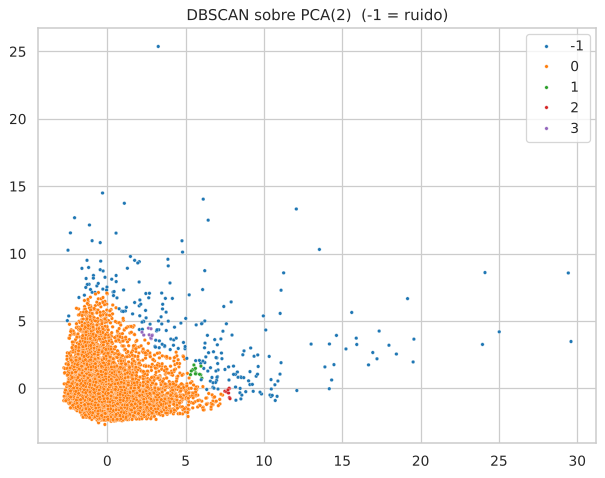

In [18]:
# Ejecutar DBSCAN sobre la proyeccion PCA(2). Observar cuantos clusters y cuanto ruido.
# Gráfico k-distancia para orientar la elección de eps
vecinos = NearestNeighbors(n_neighbors=10).fit(X_2d)
dist, _ = vecinos.kneighbors(X_2d)
plt.figure(figsize=(8, 3.5))
plt.plot(np.sort(dist[:, -1])); plt.ylabel('Distancia al 10º vecino'); plt.xlabel('Clientes ordenados')
plt.show()

db = DBSCAN(eps=0.5, min_samples=10).fit(X_2d)
conteo = pd.Series(db.labels_).value_counts()
display(conteo)
print('Clusters:', len(set(db.labels_)) - int(-1 in db.labels_),
      '| ruido:', f'{np.mean(db.labels_ == -1):.1%}')

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=db.labels_, palette='tab10', s=8)
plt.title('DBSCAN sobre PCA(2)  (-1 = ruido)')
plt.show()

**Qué observamos:** el gráfico k-distancia orienta la elección de `eps` buscando dónde la curva empieza a subir con fuerza; usamos 0,5. DBSCAN deja 8681 clientes en un cluster, forma otros tres muy pequeños y marca 239 como ruido (2,7 %).

### Visualización de los segmentos (t-SNE)

Proyectamos con t-SNE (sobre una muestra) y coloreamos por el segmento de K-Means.

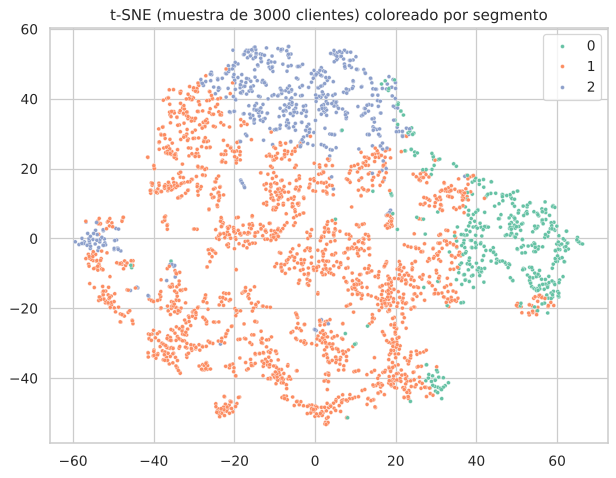

In [19]:
# t-SNE sobre una muestra de X, coloreado por el cluster de KMeans
idx = rng.choice(len(X), size=3000, replace=False)
emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(X[idx])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels_km[idx], palette='Set2', s=10)
plt.title('t-SNE (muestra de 3000 clientes) coloreado por segmento')
plt.show()

**Cómo leerlo:** cada punto es un cliente de una muestra de 3000 y el color es su segmento de K-Means. Los segmentos tienden a ocupar zonas distintas, con mezcla entre ellos. En t-SNE no se deben interpretar literalmente los tamaños ni las distancias entre zonas.

## Interpretación de los segmentos

Lo más importante en segmentación: **¿qué caracteriza a cada grupo?** Calculamos la media de cada variable por cluster y la estandarizamos entre clusters (rojo = por encima de la media, azul = por debajo). Así leemos el «perfil» de cada segmento.

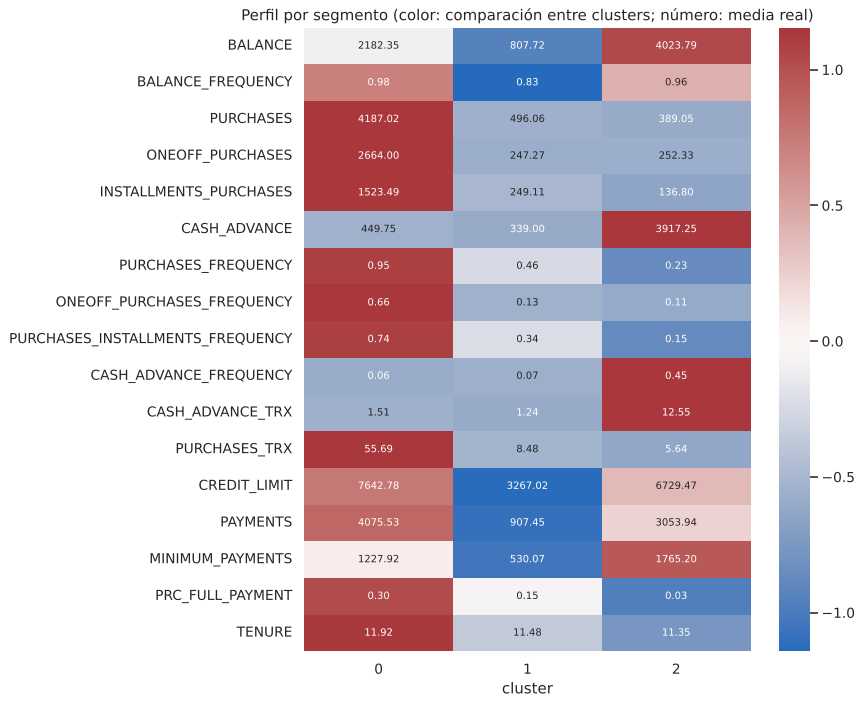

In [20]:
# 1. Anadir la columna 'cluster' al df original (sin escalar)
# 2. Calcular la media de cada variable por cluster
# 3. Estandarizar entre clusters y pintar un heatmap (perfil de cada segmento)
df_seg = df.copy()
df_seg['cluster'] = labels_km

perfil = df_seg.groupby('cluster').mean()
perfil_z = (perfil - perfil.mean()) / perfil.std()

plt.figure(figsize=(8, 9))
sns.heatmap(perfil_z.T, cmap='vlag', center=0, annot=perfil.T, fmt='.2f', annot_kws={'size': 8})
plt.title('Perfil por segmento (color: comparación entre clusters; número: media real)')
plt.show()

**Cómo leerlo:** cada columna es un cluster. El número es la media real y el color compara esa media con las de los otros dos: rojo, por encima; azul, por debajo. Un color intenso no garantiza una diferencia grande en la unidad original.

In [21]:
# Nombres asignados según el perfil (no dependen del número que K-Means dé a cada cluster)
c_compras = perfil['PURCHASES'].idxmax()
c_efectivo = perfil['CASH_ADVANCE'].idxmax()
resto = [c for c in perfil.index if c not in (c_compras, c_efectivo)]
assert best_k == 3 and len(resto) == 1, 'Revisar los nombres: cambió la segmentación'

nombres = {c_compras: 'Compradores VIP', c_efectivo: 'Dependientes de efectivo',
           resto[0]: 'Uso moderado'}
df_seg['segmento'] = df_seg['cluster'].map(nombres)

claves = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS',
          'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT']
resumen = df_seg.groupby('segmento')[claves].mean().round(2)
resumen.insert(0, 'clientes', df_seg['segmento'].value_counts())
resumen.insert(1, '%', (100 * resumen['clientes'] / len(df_seg)).round(1))
resumen.T

segmento,Compradores VIP,Dependientes de efectivo,Uso moderado
clientes,1275.00,1561.00,6114.00
%,14.20,17.40,68.30
BALANCE,2182.35,4023.79,807.72
PURCHASES,4187.02,389.05,496.06
CASH_ADVANCE,449.75,3917.25,339.00
CREDIT_LIMIT,7642.78,6729.47,3267.02
PAYMENTS,4075.53,3053.94,907.45
PURCHASES_FREQUENCY,0.95,0.23,0.46
CASH_ADVANCE_FREQUENCY,0.06,0.45,0.07
PRC_FULL_PAYMENT,0.30,0.03,0.15


**Qué hacemos:** ponemos nombre a cada grupo según su rasgo principal y resumimos cuántos clientes tiene. Los nombres son una interpretación para el negocio.

### Segmentos y estrategia de marketing

| Segmento | Peso aprox. | Qué lo caracteriza (medias) | Estrategia propuesta |
|---|---|---|---|
| **Compradores VIP** | 14 % | Compras ≈ 4.190, compran casi todos los meses (frecuencia 0,95), límite ≈ 7.640, pocos adelantos | Retención: programa de recompensas, beneficios premium, revisión de límite |
| **Uso moderado** | 68 % | Saldo ≈ 810, compras ≈ 500, límite ≈ 3.270 | Activación: incentivos por frecuencia de compra, cuotas sin interés, cashback |
| **Dependientes de efectivo** (riesgo potencial) | 17 % | Saldo ≈ 4.020, adelantos ≈ 3.920, pago total muy bajo (0,03), pocas compras | Prudencia: seguimiento de riesgo, planes de pago y educación financiera; no subir el límite sin evaluarlos |

**Cautelas:** los nombres son una interpretación nuestra. El dataset no incluye impagos, así que «riesgo» es una hipótesis a validar. El segmento moderado es muy grande y heterogéneo.

**Alternativa:** con k = 4 la silhouette baja (≈ 0,20 frente a 0,25), pero se obtiene un grupo VIP más pequeño y de mayor gasto, y el grupo moderado se divide según la frecuencia de compra. Puede ser útil si marketing necesita más detalle.

## Detección de anomalías (Isolation Forest)

Identificamos los clientes con comportamiento más atípico (posible fraude, errores de datos o clientes premium fuera de norma).

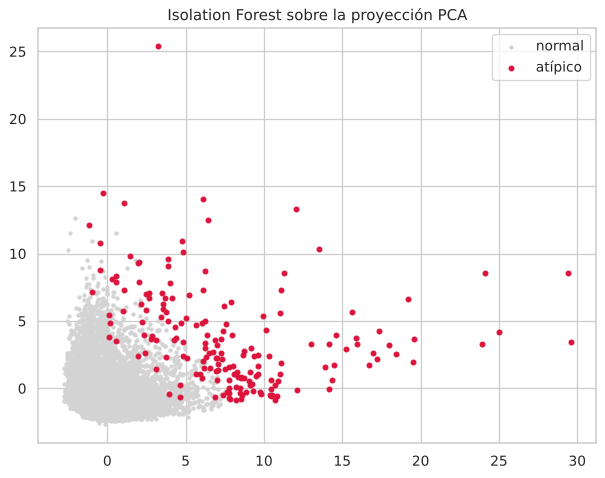

Atípicos: 179


,atípico,normal
BALANCE,5642.07,1481.26
BALANCE_FREQUENCY,0.97,0.88
PURCHASES,9799.89,823.68
ONEOFF_PURCHASES,6664.26,468.52
INSTALLMENTS_PURCHASES,3135.62,355.46
CASH_ADVANCE,4317.14,910.74
PURCHASES_FREQUENCY,0.87,0.48
ONEOFF_PURCHASES_FREQUENCY,0.66,0.19
PURCHASES_INSTALLMENTS_FREQUENCY,0.69,0.36
CASH_ADVANCE_FREQUENCY,0.28,0.13


col_0,atípico,normal
segmento,,
Compradores VIP,130,1145
Dependientes de efectivo,49,1512
Uso moderado,0,6114


In [22]:
# IsolationForest sobre X, marcar los atipicos (-1) y pintarlos sobre PCA(2)
iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE)
pred = iso.fit_predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[pred == 1, 0], X_2d[pred == 1, 1], s=6, c='lightgrey', label='normal')
plt.scatter(X_2d[pred == -1, 0], X_2d[pred == -1, 1], s=14, c='crimson', label='atípico')
plt.legend(); plt.title('Isolation Forest sobre la proyección PCA')
plt.show()

print('Atípicos:', (pred == -1).sum())
comp = df.groupby(np.where(pred == -1, 'atípico', 'normal')).mean().T
display(comp.round(2))
pd.crosstab(df_seg['segmento'], np.where(pred == -1, 'atípico', 'normal'))

**Cómo funciona:** Isolation Forest separa los datos con cortes aleatorios. Los clientes que se aíslan con menos cortes se consideran más atípicos.

Los 179 clientes marcados mueven mucho más dinero: compras medias ≈ 9.800 frente a ≈ 820 y pagos ≈ 12.640 frente a ≈ 1.510. Salen sobre todo del segmento VIP (130), algunos de efectivo (49) y ninguno de uso moderado. El 2 % lo fija `contamination`; «atípico» no implica fraude, y habría que revisar los casos uno a uno.

---
## Para ir más allá (opcional)

- **Ingeniería de KPIs**: ratio de uso del límite (`BALANCE / CREDIT_LIMIT`) o compra media por transacción.
- **UMAP / HDBSCAN** para visualización y clustering por densidad.
- **Transformación logarítmica** de las variables sesgadas antes de escalar.

## Conclusiones

- Sin etiqueta, la segmentación se valida con métricas internas y, sobre todo, con la **interpretabilidad** de los perfiles.
- Imputar con la mediana y **escalar** fueron pasos necesarios.
- PCA necesita 7 componentes para superar el 80 % de varianza; en 2D se retiene menos de la mitad.
- K-Means con k = 3 obtuvo las mejores métricas internas; Aglomerativo y sobre todo GMM dieron particiones bastante distintas.
- DBSCAN encontró un cluster dominante: mejor para señalar atípicos que para segmentar.
- Segmentos accionables: **Compradores VIP**, **Uso moderado** y **Dependientes de efectivo**.